In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
data_path = Path("../data/processed")

national = pd.read_csv(data_path / "investments_national.csv")

Основні статистики

In [4]:
print("Investment statistics:")
print(national["investment_real_2025"].describe().round(2))



Investment statistics:
count      11.00
mean      907.41
std       179.10
min       554.63
25%       808.00
50%       899.10
75%      1038.94
max      1141.75
Name: investment_real_2025, dtype: float64


In [5]:
print("\nMaximum investment:")
print(
    national.loc[
        national["investment_real_2025"].idxmax(),
        ["year","investment_real_2025"]
    ]
)

print("\nMinimum investment:")
print(
    national.loc[
        national["investment_real_2025"].idxmin(),
        ["year","investment_real_2025"]
    ]
)


Maximum investment:
year                           2018
investment_real_2025    1141.746225
Name: 3, dtype: object

Minimum investment:
year                          2022
investment_real_2025    554.633574
Name: 7, dtype: object


Графік динаміки інвестицій

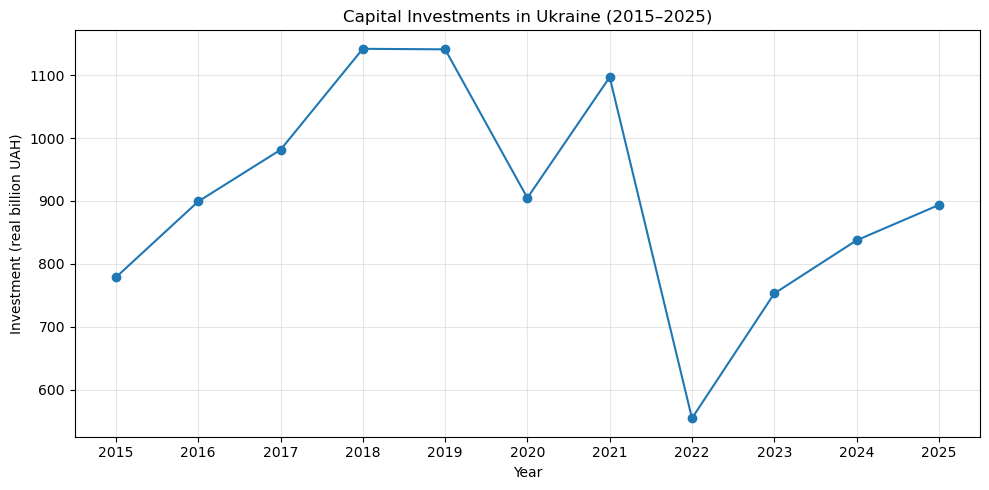

In [6]:
plt.figure(figsize=(10,5))

plt.plot(
    national["year"],
    national["investment_real_2025"],
    marker = "o"
)

plt.title("Capital Investments in Ukraine (2015–2025)")
plt.xlabel("Year")
plt.ylabel("Investment (real billion UAH)")
plt.xticks(national["year"])
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("../data/processed/national_investments.png")
plt.show()

In [7]:
table = national[["year", "investment_real_2025"]]
print(table)

    year  investment_real_2025
0   2015            778.619781
1   2016            899.103533
2   2017            981.189812
3   2018           1141.746225
4   2019           1140.892658
5   2020            904.802178
6   2021           1096.685551
7   2022            554.633574
8   2023            752.896876
9   2024            837.379387
10  2025            893.567328


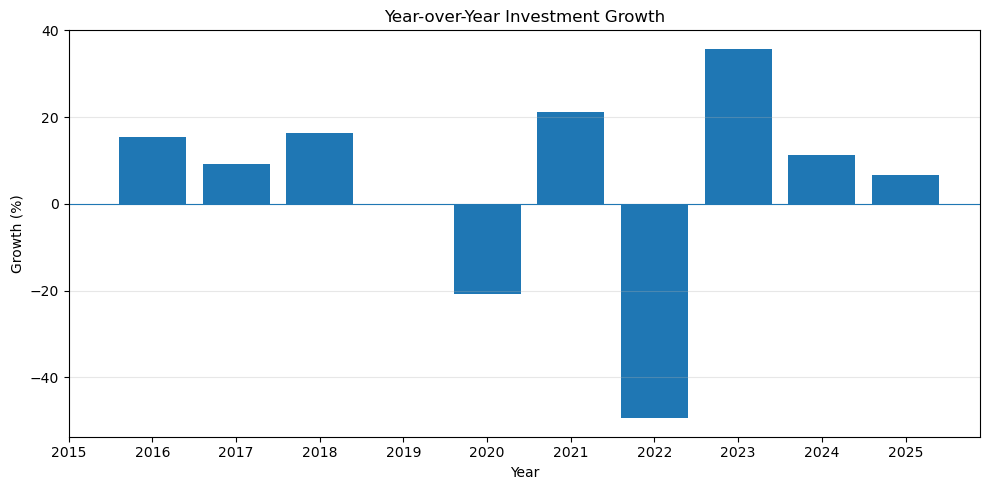

In [10]:
plt.figure(figsize=(10,5))

plt.bar(
    national["year"],
    national["real_yoy_growth_pct"]
)

plt.axhline(0, linewidth=0.8)

plt.title("Year-over-Year Investment Growth")
plt.xlabel("Year")
plt.ylabel("Growth (%)")
plt.xticks(national["year"])
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("../data/processed/investment_growth.png")
plt.show()

In [11]:
table = national[["year", "real_yoy_growth_pct"]]
print(table)

    year  real_yoy_growth_pct
0   2015                  NaN
1   2016            15.474016
2   2017             9.129792
3   2018            16.363441
4   2019            -0.074760
5   2020           -20.693488
6   2021            21.207218
7   2022           -49.426381
8   2023            35.746718
9   2024            11.220994
10  2025             6.709974


### Key Findings: Real National Investment Dynamics

During 2015–2018, real capital investment in Ukraine generally increased, reaching its highest level in the observed pre-war period at approximately UAH 1,141.7 billion in 2018 (in 2025 prices). In 2019, investment remained virtually unchanged, indicating a stagnation in real investment activity.

In 2020, real capital investment declined by 20.7% year over year. This was followed by a recovery in 2021, when investment increased by 21.2%, although it remained below the 2018–2019 level.

The most significant decline occurred in 2022, when real capital investment fell by 49.4% year over year, coinciding with Russia's full-scale invasion of Ukraine.

In 2023, investment increased by 35.7%, indicating a substantial recovery from the low 2022 base. However, this recovery remained incomplete: by 2025, real capital investment had reached approximately UAH 893.6 billion, still around 21.6% below the 2021 level and 21.7% below the 2018 peak.

Overall, the data indicate that despite the recovery observed in 2023–2025, real capital investment in Ukraine had not returned to its pre-war peak by the end of the observed period.

**Limitation:** Real investment values are estimated using the average annual Consumer Price Index (CPI), with all values adjusted to 2025 prices. Since CPI is not a specialized deflator for capital investment, the resulting figures should be interpreted as an approximation of real investment dynamics.

5.2. Регіональний аналіз

In [12]:
regional = pd.read_csv(data_path / "investments_regional.csv")

# Топ-10 регіонів за обсягом інвестицій у 2025 році

In [16]:
top_regions = (
    regional[regional["year"] == 2025 ]
    .sort_values("investment_real_2025", ascending= False)
    .head(10)
)

print("Top 10 regions in 2025:")
print(
    top_regions[
        ["region","investment_real_2025"]
    ].to_string(index= False)
)

Top 10 regions in 2025:
          region  investment_real_2025
            Київ            333.006776
Дніпропетровська             86.988180
        Київська             73.252003
       Львівська             65.146798
      Харківська             29.021760
      Полтавська             27.834184
       Вінницька             27.482817
         Одеська             24.202982
       Волинська             22.485480
     Хмельницька             20.375247


# Частка регіонів у загальному обсязі інвестицій

In [18]:
total_investment_2025 = national.loc[
    national["year"] == 2025,
    "investment_real_2025"
].iloc[0]

top_regions = top_regions.copy()

top_regions["investment_share_pct"] = (
    top_regions["investment_real_2025"]
    / total_investment_2025 * 100
)

print("Top 10 regional shares:")
print(
    top_regions[
        ["region","investment_share_pct"]
    ].to_string(index=False)
)

print(
    f"Combined share of Top 10: "
    f"{top_regions['investment_share_pct'].sum():.2f}%"
)

Top 10 regional shares:
          region  investment_share_pct
            Київ             37.267116
Дніпропетровська              9.734933
        Київська              8.197704
       Львівська              7.290642
      Харківська              3.247854
      Полтавська              3.114951
       Вінницька              3.075629
         Одеська              2.708580
       Волинська              2.516372
     Хмельницька              2.280214
Combined share of Top 10: 79.43%


# Візуалізація

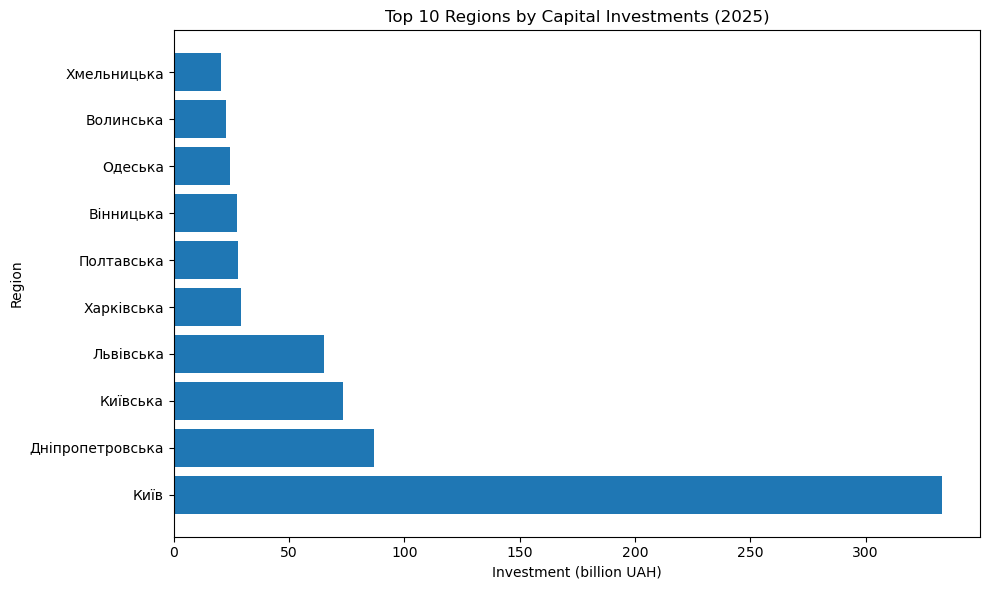

In [19]:
plt.figure(figsize=(10,6))

plt.barh(
    top_regions["region"],
    top_regions["investment_real_2025"]
)

plt.title("Top 10 Regions by Capital Investments (2025)")
plt.xlabel("Investment (billion UAH)")
plt.ylabel("Region")
plt.gca().invert_yaxis

plt.tight_layout()
plt.savefig("../data/processed/regional_top10_2025.png")
plt.show()

У 2025 році регіональний розподіл капітальних інвестицій в Україні характеризувався високою концентрацією. На місто Київ припадало 37,27% загального обсягу інвестицій — майже вчетверо більше, ніж на Дніпропетровську область (9,73%).

Наступними за обсягом були Київська (8,20%) та Львівська (7,29%) області. Разом із Дніпропетровською областю вони формували ще 25,22% загального обсягу.

Десять найбільших регіонів забезпечували 79,43% усіх капітальних інвестицій, тоді як на решту регіонів припадало лише 20,57%.

## Regional Investment Comparison: 2021 vs 2025

The objective is to examine changes in the regional distribution
of capital investments between the pre-war and wartime periods.

In [21]:
# Вибираємо дані за 2021 та 2025 роки
comparison = regional[
    regional["year"].isin([2021, 2025])
].copy()

# Перевіряємо результат
print(comparison.head())
print(comparison.shape)

               region  year  investment_thousand_uah  investment_billion_uah  \
6   Івано-Франківська  2021               12281979.0               12.281979   
10  Івано-Франківська  2025               16471045.0               16.471045   
17          Волинська  2021               11718339.0               11.718339   
21          Волинська  2025               22485480.0               22.485480   
28          Вінницька  2021               16922083.0               16.922083   

    cpi_pct  deflator_to_2025  investment_real_2025  nominal_yoy_growth_pct  \
6       9.4          1.627373             19.987360               93.782341   
10     12.7          1.000000             16.471045               -1.805291   
17      9.4          1.627373             19.070108               28.468303   
21     12.7          1.000000             22.485480               12.459029   
28      9.4          1.627373             27.538540               24.413240   

    real_yoy_growth_pct  
6             77.1

In [22]:
# Загальний обсяг інвестицій за кожен рік
year_totals = (
    national[national["year"].isin([2021, 2025])]
    .set_index("year")["investment_real_2025"]
)

# Частка кожного регіону в загальному обсязі
comparison["investment_share_pct"] = comparison.apply(
    lambda row: (
        row["investment_real_2025"]
        / year_totals.loc[row["year"]]
        * 100
    ),
    axis=1
)

print(comparison.head())

               region  year  investment_thousand_uah  investment_billion_uah  \
6   Івано-Франківська  2021               12281979.0               12.281979   
10  Івано-Франківська  2025               16471045.0               16.471045   
17          Волинська  2021               11718339.0               11.718339   
21          Волинська  2025               22485480.0               22.485480   
28          Вінницька  2021               16922083.0               16.922083   

    cpi_pct  deflator_to_2025  investment_real_2025  nominal_yoy_growth_pct  \
6       9.4          1.627373             19.987360               93.782341   
10     12.7          1.000000             16.471045               -1.805291   
17      9.4          1.627373             19.070108               28.468303   
21     12.7          1.000000             22.485480               12.459029   
28      9.4          1.627373             27.538540               24.413240   

    real_yoy_growth_pct  investment_share_pc

In [23]:
# Перетворюємо таблицю: один рядок = один регіон
share_comparison = comparison.pivot(
    index="region",
    columns="year",
    values="investment_share_pct"
).reset_index()

share_comparison.columns.name = None

# Розраховуємо зміну частки у відсоткових пунктах
share_comparison["share_change_pp"] = (
    share_comparison[2025] - share_comparison[2021]
)

# Сортуємо за найбільшим приростом частки
share_comparison = share_comparison.sort_values(
    "share_change_pp",
    ascending=False
)

print(share_comparison.round(2).to_string(index=False))

           region  2021  2025  share_change_pp
             Київ 30.37 37.27             6.89
        Львівська  4.67  7.29             2.62
         Київська  6.57  8.20             1.63
     Закарпатська  1.36  2.24             0.87
        Волинська  1.74  2.52             0.78
        Вінницька  2.51  3.08             0.56
        Черкаська  1.83  2.27             0.44
      Житомирська  1.70  2.02             0.32
    Тернопільська  1.58  1.89             0.31
     Чернігівська  1.53  1.83             0.30
      Хмельницька  2.01  2.28             0.27
      Чернівецька  0.64  0.75             0.11
          Сумська  1.57  1.67             0.11
Івано-Франківська  1.82  1.84             0.02
   Кіровоградська  1.29  1.21            -0.08
     Миколаївська  1.80  1.53            -0.27
       Харківська  3.66  3.25            -0.41
        Луганська  0.67  0.01            -0.66
          Одеська  3.58  2.71            -0.87
       Полтавська  4.16  3.11            -1.05
       Рівнен

In [24]:
# Частки регіонів за кожен рік
for year in [2021, 2025]:
    shares = comparison[
        comparison["year"] == year
    ]["investment_share_pct"].sort_values(ascending=False)

    print(f"\nYear: {year}")
    print(f"Top 3 share: {shares.head(3).sum():.2f}%")
    print(f"Top 5 share: {shares.head(5).sum():.2f}%")
    print(f"Top 10 share: {shares.head(10).sum():.2f}%")


Year: 2021
Top 3 share: 48.59%
Top 5 share: 58.08%
Top 10 share: 75.79%

Year: 2025
Top 3 share: 55.20%
Top 5 share: 65.74%
Top 10 share: 79.43%


### Regional Investment Concentration: 2021 vs 2025

The analysis indicates an increase in the concentration of capital investment across Ukrainian regions between 2021 and 2025.

The combined share of the three largest regions increased from 48.59% to 55.20% (+6.61 percentage points). The five largest regions increased their combined share from 58.08% to 65.74% (+7.66 percentage points).

The concentration among the ten largest regions also increased, from 75.79% to 79.43% (+3.64 percentage points).

These findings suggest that capital investment distribution became more concentrated in the largest investment destinations during the observed period.

**Limitations:** Regional shares are calculated using each region's contribution to total national capital investment. Since the same annual CPI adjustment factor applies to all regions, the regional shares remain unchanged when nominal values are converted into estimated real values. However, the comparison is affected by changes in regional statistical coverage, particularly in temporarily occupied and conflict-affected territories. The observed changes should not be interpreted as direct evidence that the full-scale invasion alone caused the increased concentration.

## Regional Investment Structure: Pre-war vs Wartime Periods

This section compares the average regional distribution of capital
investments between 2015–2021 and 2022–2025.

In [25]:
# Перевіряємо кількість регіонів у кожному році
region_counts = (
    regional.groupby("year")["region"]
    .nunique()
)

print("Number of regions by year:")
print(region_counts)

Number of regions by year:
year
2015    25
2016    25
2017    25
2018    25
2019    25
2020    25
2021    25
2022    25
2023    25
2024    25
2025    25
Name: region, dtype: int64


In [26]:
# Перевіряємо пропущені значення
print(regional.isna().sum())

# Перевіряємо дублікати регіон-рік
print(
    "Duplicate region-year pairs:",
    regional.duplicated(["region", "year"]).sum()
)

region                      0
year                        0
investment_thousand_uah     0
investment_billion_uah      0
cpi_pct                     0
deflator_to_2025            0
investment_real_2025        0
nominal_yoy_growth_pct     25
real_yoy_growth_pct        25
dtype: int64
Duplicate region-year pairs: 0


In [27]:
# Загальний обсяг інвестицій за кожен рік
year_totals = (
    national.set_index("year")["investment_real_2025"]
)

# Частка кожного регіону в інвестиціях відповідного року
regional_shares = regional.copy()

regional_shares["investment_share_pct"] = (
    regional_shares.apply(
        lambda row: (
            row["investment_real_2025"]
            / year_totals.loc[row["year"]]
            * 100
        ),
        axis=1
    )
)

In [28]:
# Визначаємо періоди
regional_shares["period"] = regional_shares["year"].apply(
    lambda year: (
        "Pre-war (2015–2021)"
        if year <= 2021
        else "Wartime (2022–2025)"
    )
)

# Середня частка кожного регіону за період
period_comparison = (
    regional_shares
    .groupby(["region", "period"])["investment_share_pct"]
    .mean()
    .unstack()
    .reset_index()
)

# Різниця між періодами
period_comparison["share_change_pp"] = (
    period_comparison["Wartime (2022–2025)"]
    - period_comparison["Pre-war (2015–2021)"]
)

# Сортуємо за найбільшим зростанням
period_comparison = period_comparison.sort_values(
    "share_change_pp",
    ascending=False
)

print(period_comparison.round(2).to_string(index=False))

           region  Pre-war (2015–2021)  Wartime (2022–2025)  share_change_pp
             Київ                31.92                35.70             3.78
        Львівська                 4.97                 6.80             1.84
       Рівненська                 1.54                 2.21             0.67
        Волинська                 1.81                 2.38             0.57
        Вінницька                 2.63                 3.19             0.57
     Чернігівська                 1.49                 2.03             0.54
    Тернопільська                 1.47                 2.00             0.53
     Закарпатська                 1.30                 1.82             0.52
        Черкаська                 1.80                 2.25             0.45
         Київська                 7.72                 8.10             0.38
      Житомирська                 1.59                 1.87             0.28
      Хмельницька                 2.16                 2.31             0.15

### Regional Investment Structure: Pre-war vs Wartime Periods

The comparison of average regional investment shares between 2015–2021 and 2022–2025 reveals changes in the geographical distribution of capital investments in Ukraine.

Kyiv recorded the largest increase in its average share, rising from 31.92% to 35.70% (+3.78 percentage points). Lviv region also experienced a notable increase (+1.84 pp), alongside several other western and central regions.

In contrast, the largest decreases were observed in Donetsk (-3.35 pp), Kherson (-1.46 pp), Zaporizhzhia (-1.44 pp), and Kharkiv (-1.04 pp) regions.

Overall, the results indicate a greater relative concentration of capital investments in Kyiv and several western and central regions during 2022–2025.

**Limitations:** The analysis compares average annual regional shares, giving equal weight to each year. Since the same annual CPI adjustment factor applies to all regions, the results are identical for nominal and estimated real investment shares. Regional statistical coverage changed during the war, particularly in occupied and conflict-affected territories. These findings indicate structural changes but do not establish that the war alone caused them.

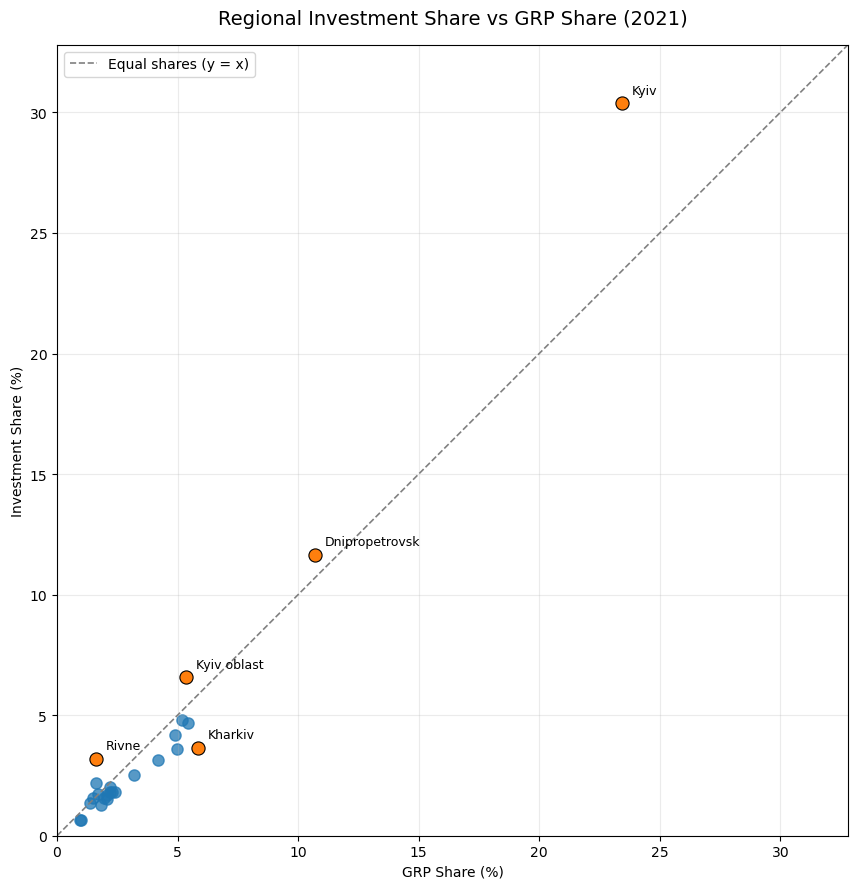

In [5]:
comparison = pd.read_csv(
    "../data/processed/regional_investment_grp_comparison_2021.csv"
)

fig, ax = plt.subplots(figsize=(9, 9))

# All regions
ax.scatter(
    comparison["grp_share_pct"],
    comparison["investment_share_pct"],
    s=65,
    alpha=0.75
)

# Highlight selected regions
highlight_regions = {
    "Київ": "Kyiv",
    "Дніпропетровська": "Dnipropetrovsk",
    "Рівненська": "Rivne",
    "Харківська": "Kharkiv",
    "Київська": "Kyiv oblast"
}

highlight = comparison[
    comparison["region"].isin(highlight_regions.keys())
]

ax.scatter(
    highlight["grp_share_pct"],
    highlight["investment_share_pct"],
    s=90,
    edgecolors="black",
    linewidths=0.8,
    zorder=3
)

# Equality line
max_value = max(
    comparison["grp_share_pct"].max(),
    comparison["investment_share_pct"].max()
)

axis_limit = max_value * 1.08

ax.plot(
    [0, axis_limit],
    [0, axis_limit],
    linestyle="--",
    linewidth=1.2,
    color="gray",
    label="Equal shares (y = x)"
)

# Annotations
for _, row in highlight.iterrows():
    label = highlight_regions[row["region"]]

    ax.annotate(
        label,
        (row["grp_share_pct"], row["investment_share_pct"]),
        xytext=(7, 7),
        textcoords="offset points",
        fontsize=9
    )

# Formatting
ax.set_title(
    "Regional Investment Share vs GRP Share (2021)",
    fontsize=14,
    pad=15
)

ax.set_xlabel("GRP Share (%)")
ax.set_ylabel("Investment Share (%)")

ax.set_xlim(0, axis_limit)
ax.set_ylim(0, axis_limit)

# Equal scale for both axes
ax.set_aspect("equal", adjustable="box")

ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()


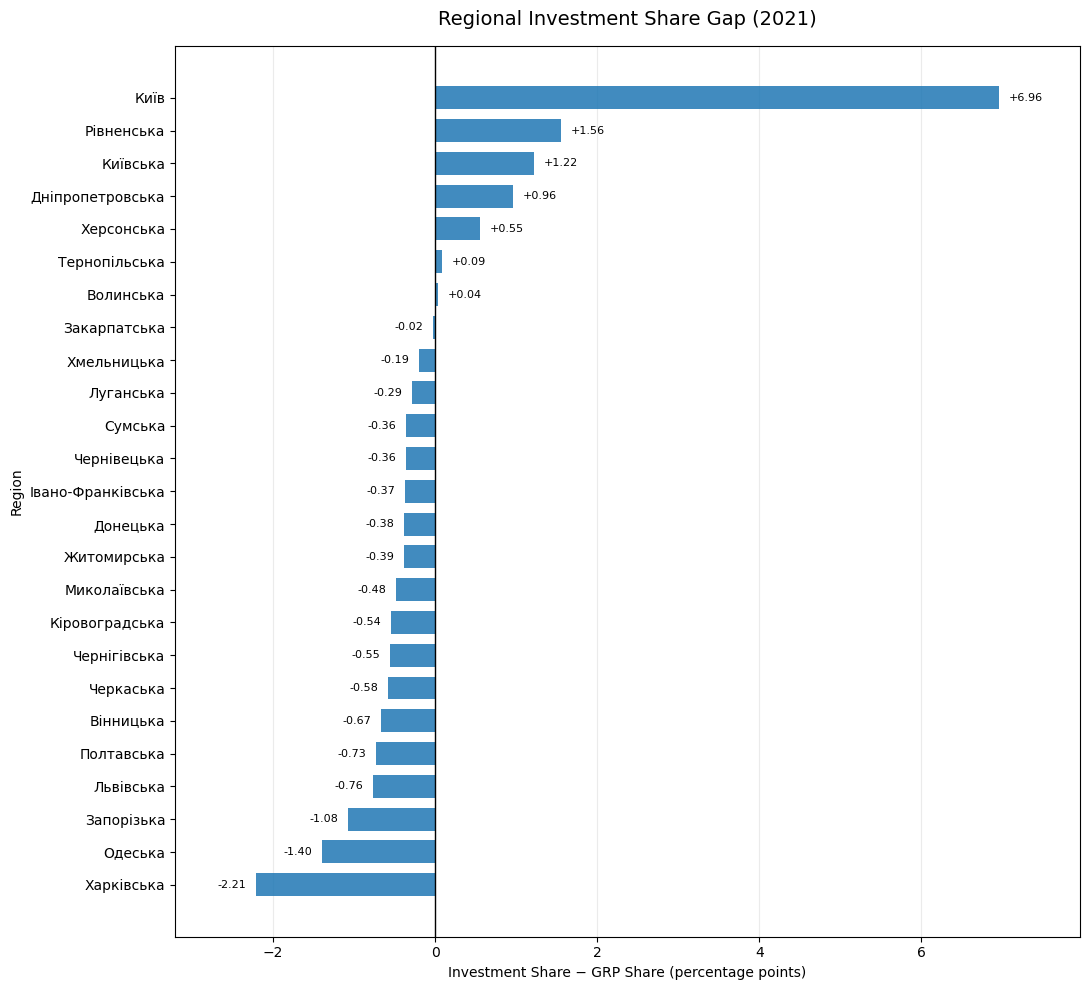

In [6]:
# Sort regions by investment-GRP share gap
comparison = comparison.sort_values(
    "share_gap_pp",
    ascending=True
)

fig, ax = plt.subplots(figsize=(11, 10))

# Horizontal bar chart
ax.barh(
    comparison["region"],
    comparison["share_gap_pp"],
    height=0.7,
    alpha=0.85
)

# Zero reference line
ax.axvline(
    0,
    color="black",
    linewidth=1
)

# Labels and formatting
ax.set_title(
    "Regional Investment Share Gap (2021)",
    fontsize=14,
    pad=15
)

ax.set_xlabel("Investment Share − GRP Share (percentage points)")
ax.set_ylabel("Region")

ax.grid(
    axis="x",
    alpha=0.25
)

ax.set_axisbelow(True)

# Add value labels
for bar in ax.patches:
    width = bar.get_width()
    y = bar.get_y() + bar.get_height() / 2

    offset = 0.12

    if width >= 0:
        ax.text(
            width + offset,
            y,
            f"+{width:.2f}",
            va="center",
            ha="left",
            fontsize=8
        )
    else:
        ax.text(
            width - offset,
            y,
            f"{width:.2f}",
            va="center",
            ha="right",
            fontsize=8
        )

# Adjust x-axis limits for labels
min_gap = comparison["share_gap_pp"].min()
max_gap = comparison["share_gap_pp"].max()

ax.set_xlim(
    min_gap - 1.0,
    max_gap + 1.0
)

plt.tight_layout()
plt.show()


In [9]:

# Top 5 positive and negative gaps
top_positive = comparison.nlargest(5, "share_gap_pp")

top_negative = comparison.nsmallest(5, "share_gap_pp")

selected_regions = pd.concat([
    top_positive,
    top_negative
]).sort_values("share_gap_pp", ascending=False)

# Select relevant columns
summary_table = selected_regions[
    [
        "region",
        "investment_share_pct",
        "grp_share_pct",
        "share_gap_pp"
    ]
].copy()

summary_table.columns = [
    "Region",
    "Investment Share (%)",
    "GRP Share (%)",
    "Gap (pp)"
]
summary_table = summary_table.rename(
    columns={"Gap (pp)": "Share Gap (pp)"}
)

display(
    display(
    summary_table
    .round(2)
    .reset_index(drop=True)
    .style.format({
        "Investment Share (%)": "{:.2f}",
        "GRP Share (%)": "{:.2f}",
        "Share Gap (pp)": "{:+.2f}"
    })
)
)


,Region,Investment Share (%),GRP Share (%),Share Gap (pp)
0,Київ,30.37,23.42,+6.96
1,Рівненська,3.19,1.63,+1.56
2,Київська,6.57,5.35,+1.22
3,Дніпропетровська,11.65,10.68,+0.96
4,Херсонська,2.17,1.62,+0.55
5,Полтавська,4.16,4.89,-0.73
6,Львівська,4.67,5.43,-0.76
7,Запорізька,3.12,4.20,-1.08
8,Одеська,3.58,4.98,-1.40
9,Харківська,3.66,5.87,-2.21


None

## Capital Investments vs Rule of Law Index

This section explores the relationship between capital investment
dynamics and the World Justice Project Rule of Law Index in Ukraine
during 2015–2021.

The analysis is descriptive and does not aim to establish causality.

In [29]:
combined = pd.read_csv(data_path / "combined_national.csv")

print("Dataset shape:", combined.shape)
print("\nAvailable columns:")
print(combined.columns.tolist())

print("\nInvestment and Rule of Law data:")
print(
    combined[
        ["year", "investment_real_2025", "overall_score"]
    ].to_string(index=False)
)

Dataset shape: (6, 12)

Available columns:
['year', 'investment_billion_uah', 'investment_real_2025', 'overall_score', 'factor_1', 'factor_2', 'factor_3', 'factor_4', 'factor_5', 'factor_6', 'factor_7', 'factor_8']

Investment and Rule of Law data:
     year  investment_real_2025  overall_score
     2015            778.619781       0.480531
     2016            899.103533       0.489450
2017-2018           1061.468019       0.497254
     2019           1140.892658       0.502246
     2020            904.802178       0.506458
     2021           1096.685551       0.509684


In [30]:
# Normalize both indicators: 2015 = 100

combined["investment_index"] = (
    combined["investment_real_2025"]
    / combined.loc[combined["year"] == "2015", "investment_real_2025"].iloc[0]
    * 100
)

combined["rule_of_law_index"] = (
    combined["overall_score"]
    / combined.loc[combined["year"] == "2015", "overall_score"].iloc[0]
    * 100
)

display(
    combined[
        ["year", "investment_index", "rule_of_law_index"]
    ].round(2)
)

,year,investment_index,rule_of_law_index
0,2015,100.00,100.00
1,2016,115.47,101.86
2,2017-2018,136.33,103.48
3,2019,146.53,104.52
4,2020,116.21,105.40
5,2021,140.85,106.07


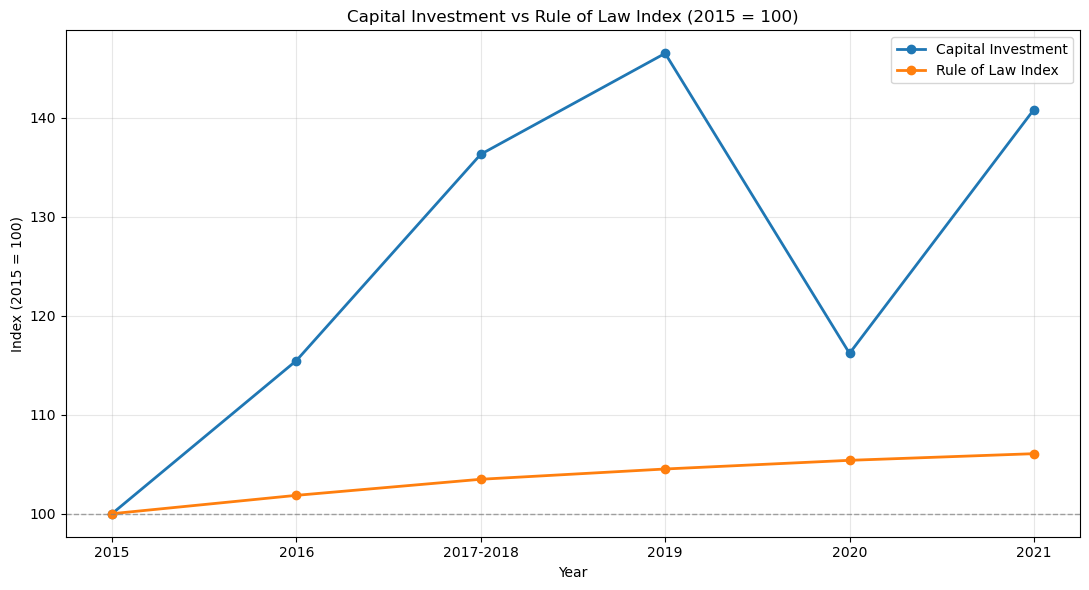

In [46]:
plt.figure(figsize=(11, 6))

plt.plot(
    combined["year"],
    combined["investment_index"],
    marker="o",
    linewidth=2,
    label="Capital Investment"
)

plt.plot(
    combined["year"],
    combined["rule_of_law_index"],
    marker="o",
    linewidth=2,
    label="Rule of Law Index"
)

plt.axhline(
    y=100,
    color="gray",
    linestyle="--",
    linewidth=1,
    alpha=0.7
)

plt.title("Capital Investment vs Rule of Law Index (2015 = 100)")
plt.xlabel("Year")
plt.ylabel("Index (2015 = 100)")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [31]:
# Pearson and Spearman correlation

pearson_corr = combined[
    ["investment_real_2025", "overall_score"]
].corr(method="pearson").iloc[0, 1]

spearman_corr = combined[
    ["investment_real_2025", "overall_score"]
].corr(method="spearman").iloc[0, 1]

print(f"Pearson correlation: {pearson_corr:.3f}")
print(f"Spearman correlation: {spearman_corr:.3f}")

Pearson correlation: 0.719
Spearman correlation: 0.714


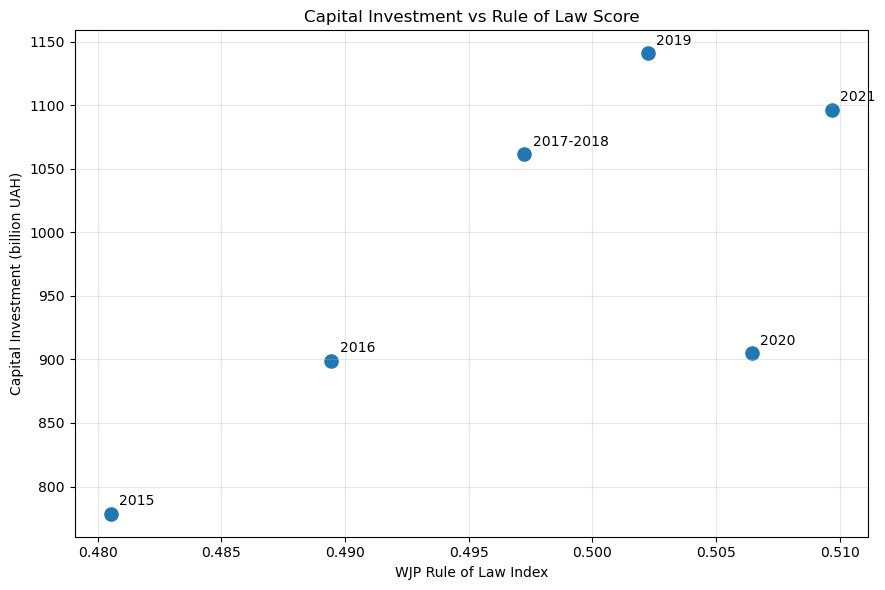

In [32]:
plt.figure(figsize=(9, 6))

plt.scatter(
    combined["overall_score"],
    combined["investment_real_2025"],
    s=90
)

for _, row in combined.iterrows():
    plt.annotate(
        row["year"],
        (row["overall_score"], row["investment_real_2025"]),
        xytext=(6, 6),
        textcoords="offset points"
    )

plt.title("Capital Investment vs Rule of Law Score")
plt.xlabel("WJP Rule of Law Index")
plt.ylabel("Capital Investment (billion UAH)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Relationship Between Real Capital Investment and the Rule of Law Index

During 2015–2021, real capital investment and the overall WJP Rule of Law Index in Ukraine demonstrated a positive correlation (Pearson = 0.719; Spearman = 0.714). However, the relationship was notably weaker than in the analysis based on nominal investment values.

The difference between nominal and real investment correlations suggests that inflation-related growth in nominal investment values may have contributed to the stronger association observed in the initial analysis.

The dynamics of the two indicators were not fully synchronized. In 2020, real capital investment declined by 20.7%, while the WJP score continued to increase. In 2021, investment recovered by 21.2%, although it remained below its 2019 level, while the Rule of Law Index continued its gradual upward trend.

Overall, the results indicate a positive association between real capital investment and the Rule of Law Index, but the relationship is less pronounced after adjusting investment values for inflation.

**Limitations:** The analysis is based on only six observations, with the 2017–2018 period represented by a single combined WJP edition. Both indicators may also be influenced by underlying time trends. Therefore, the observed correlation should be interpreted as a descriptive association rather than evidence of a causal relationship.

In [33]:
# Select investment and all WJP factors
correlation_data = combined[
    ["investment_real_2025"] +
    [f"factor_{i}" for i in range(1, 9)]
]

# Calculate Pearson correlation matrix
correlation_matrix = correlation_data.corr(method="pearson")

# Display correlation matrix
display(correlation_matrix.round(2))

,investment_real_2025,factor_1,factor_2,factor_3,factor_4,factor_5,factor_6,factor_7,factor_8
investment_real_2025,1.00,0.41,-0.49,-0.26,-0.45,0.76,0.36,0.69,0.09
factor_1,0.41,1.00,-0.80,0.74,-0.29,0.70,0.85,0.77,-0.32
factor_2,-0.49,-0.80,1.00,-0.48,0.70,-0.71,-0.98,-0.94,0.74
factor_3,-0.26,0.74,-0.48,1.00,-0.14,0.27,0.63,0.31,-0.40
factor_4,-0.45,-0.29,0.70,-0.14,1.00,-0.64,-0.63,-0.67,0.70
factor_5,0.76,0.70,-0.71,0.27,-0.64,1.00,0.63,0.88,-0.23
factor_6,0.36,0.85,-0.98,0.63,-0.63,0.63,1.00,0.86,-0.73
factor_7,0.69,0.77,-0.94,0.31,-0.67,0.88,0.86,1.00,-0.54
factor_8,0.09,-0.32,0.74,-0.40,0.70,-0.23,-0.73,-0.54,1.00


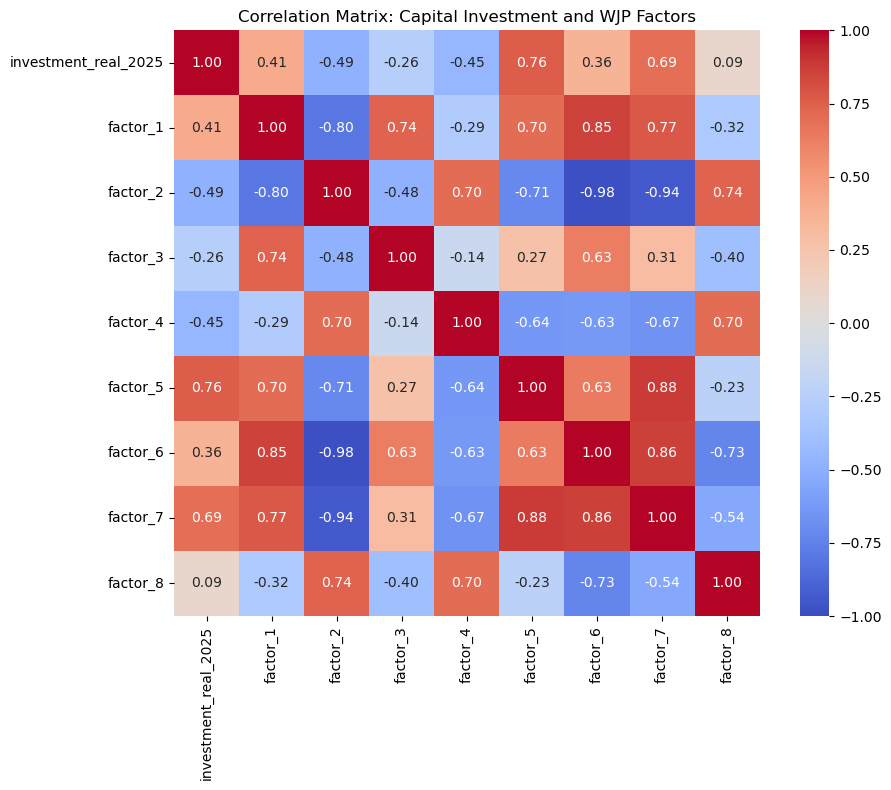

In [50]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Correlation Matrix: Capital Investment and WJP Factors")
plt.tight_layout()
plt.show()

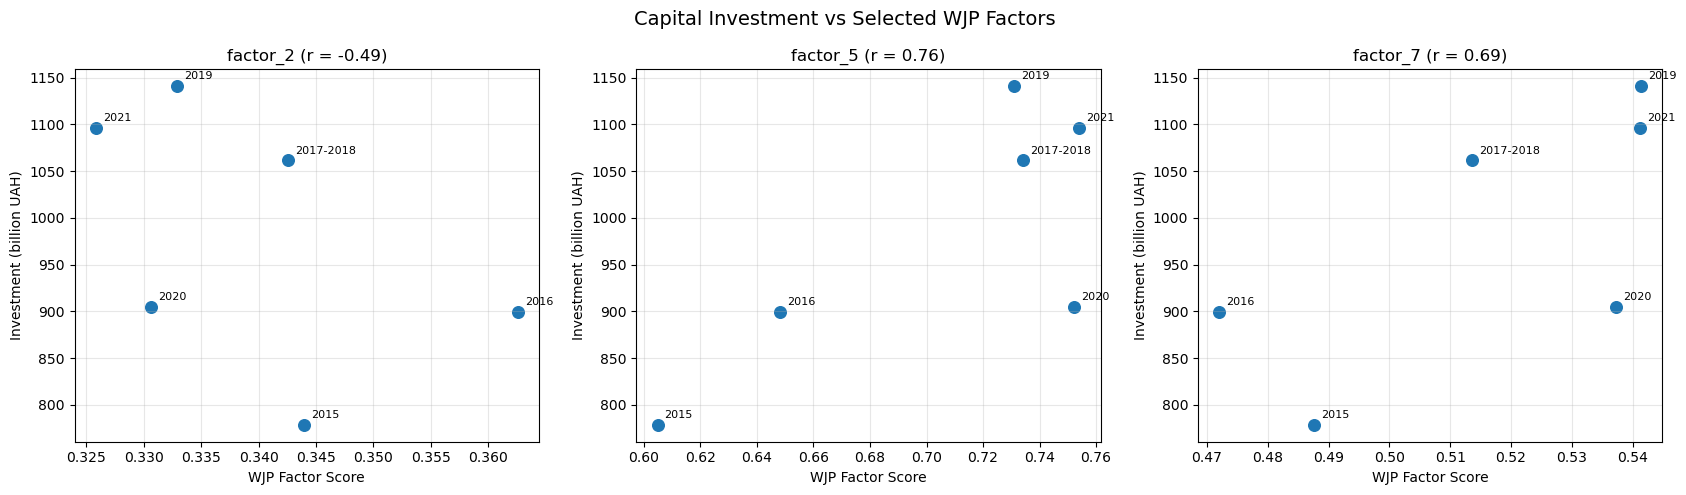

In [35]:
# Selected factors for deeper analysis
selected_factors = ["factor_2", "factor_5", "factor_7"]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, factor in zip(axes, selected_factors):
    corr = combined["investment_real_2025"].corr(
        combined[factor]
    )

    ax.scatter(
        combined[factor],
        combined["investment_real_2025"],
        s=70
    )

    for _, row in combined.iterrows():
        ax.annotate(
            row["year"],
            (row[factor], row["investment_real_2025"]),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=8
        )

    ax.set_title(f"{factor} (r = {corr:.2f})")
    ax.set_xlabel("WJP Factor Score")
    ax.set_ylabel("Investment (billion UAH)")
    ax.grid(alpha=0.3)

plt.suptitle(
    "Capital Investment vs Selected WJP Factors",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [34]:
selected_factors = ["factor_2", "factor_5", "factor_7"]

results = []

for factor in selected_factors:
    for year in combined["year"]:
        subset = combined[combined["year"] != year]

        corr = subset["investment_real_2025"].corr(
            subset[factor],
            method="pearson"
        )

        results.append({
            "factor": factor,
            "excluded_year": year,
            "pearson_correlation": corr
        })

robustness_check = pd.DataFrame(results)

display(
    robustness_check.pivot(
        index="excluded_year",
        columns="factor",
        values="pearson_correlation"
    ).round(3)
)

factor,factor_2,factor_5,factor_7
excluded_year,,,
2015,-0.534,0.487,0.583
2016,-0.482,0.743,0.726
2017-2018,-0.540,0.749,0.729
2019,-0.428,0.798,0.603
2020,-0.632,0.967,0.869
2021,-0.352,0.720,0.626


In [53]:

# Represent years numerically
time = np.array([2015, 2016, 2017.5, 2019, 2020, 2021])

variables = [
    "investment_real_2025",
    "factor_2",
    "factor_5",
    "factor_7"
]

# Remove linear time trend
detrended = pd.DataFrame(index=combined.index)

for column in variables:
    values = combined[column].values

    trend = np.polyval(
        np.polyfit(time, values, 1),
        time
    )

    detrended[column] = values - trend

# Correlation between detrended values
detrended_corr = detrended.corr()

display(
    detrended_corr.loc[
        "investment_real_2025",
        ["factor_2", "factor_5", "factor_7"]
    ].to_frame("detrended_correlation").round(3)
)

,detrended_correlation
factor_2,0.138
factor_5,0.529
factor_7,0.281


### Correlation Between Real Capital Investment and WJP Factors

The correlation analysis between real capital investment and individual WJP factors revealed different patterns across institutional dimensions.

The strongest positive correlations were observed for Order and Security (Factor 5, Pearson = 0.76) and Civil Justice (Factor 7, Pearson = 0.69). In contrast, Absence of Corruption (Factor 2) demonstrated a moderate negative correlation (Pearson = -0.49).

Leave-one-out analysis showed that the direction of these three relationships remained unchanged across all six model variations. However, the magnitude of the correlations varied considerably, indicating sensitivity to individual observations.

After removing linear time trends, the correlation with Factor 5 remained moderately positive (0.529), while the relationships with Factor 2 (0.138) and Factor 7 (0.281) became considerably weaker.

Overall, Order and Security (Factor 5) demonstrated the most consistent positive association with real capital investment among the selected WJP factors. Nevertheless, the results remain exploratory and do not establish an independent or causal relationship between institutional conditions and investment activity.

**Limitations:** The analysis is based on only six observations, which substantially limits the reliability of correlation estimates and robustness checks. Leave-one-out results are sensitive to individual observations, while detrended correlations provide only preliminary diagnostic evidence. The findings should therefore be interpreted as exploratory rather than conclusive.